In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

warnings.filterwarnings('ignore')

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("All libraries imported successfully!")

All libraries imported successfully!


**Load the HR dataset**

In [3]:
from google.colab import files
import glob

csv_files = glob.glob('/content/*.csv')

if not csv_files:
    uploaded = files.upload()
    csv_files = glob.glob('/content/*.csv')

df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


**Inspect the dataset**

In [4]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe(include='all').T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  Job

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


**Check missing values**

In [5]:
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    'Column': df.columns,
    'Missing Values': missing_values.values,
    'Missing Percentage':
        (missing_values.values / len(df)) * 100
})

display(missing_report)

print("Total Missing Values:", df.isnull().sum().sum())

,Column,Missing Values,Missing Percentage
0,Age,0,0.0
1,Attrition,0,0.0
2,BusinessTravel,0,0.0
3,DailyRate,0,0.0
4,Department,0,0.0
5,DistanceFromHome,0,0.0
6,Education,0,0.0
7,EducationField,0,0.0
8,EmployeeCount,0,0.0
9,EmployeeNumber,0,0.0


Total Missing Values: 0


**Handle missing values**

In [6]:
df_clean = df.copy()

numeric_columns = df_clean.select_dtypes(
    include=np.number
).columns

categorical_columns = df_clean.select_dtypes(
    include='object'
).columns

# Fill numerical missing values with median
for col in numeric_columns:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Fill categorical missing values with mode
for col in categorical_columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode()[0]
        )

print("Missing values handled successfully!")
print("Remaining Missing Values:",
      df_clean.isnull().sum().sum())

Missing values handled successfully!
Remaining Missing Values: 0


**Handle duplicate records**

In [7]:
duplicates = df_clean.duplicated().sum()

print("Duplicate Records Found:", duplicates)

df_clean = df_clean.drop_duplicates()

print("Dataset Shape After Removing Duplicates:",
      df_clean.shape)

print("Remaining Duplicates:",
      df_clean.duplicated().sum())

Duplicate Records Found: 0
Dataset Shape After Removing Duplicates: (1470, 35)
Remaining Duplicates: 0


**Detect outliers**

In [8]:
numeric_columns = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

# Exclude identifier and constant columns
exclude_columns = [
    'EmployeeNumber',
    'EmployeeCount',
    'Over18',
    'StandardHours'
]

numeric_columns = [
    col for col in numeric_columns
    if col not in exclude_columns
]

outlier_results = []

for col in numeric_columns:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ).sum()

    outlier_results.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outliers
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report)

,Feature,Lower Bound,Upper Bound,Outlier Count
0,Age,10.500,62.500,0
1,DailyRate,-573.000,2195.000,0
2,DistanceFromHome,-16.000,32.000,0
3,Education,-1.000,7.000,0
4,EnvironmentSatisfaction,-1.000,7.000,0
5,HourlyRate,-5.625,137.375,0
6,JobInvolvement,0.500,4.500,0
7,JobLevel,-2.000,6.000,0
8,JobSatisfaction,-1.000,7.000,0
9,MonthlyIncome,-5291.000,16581.000,114


**Visualize outliers**

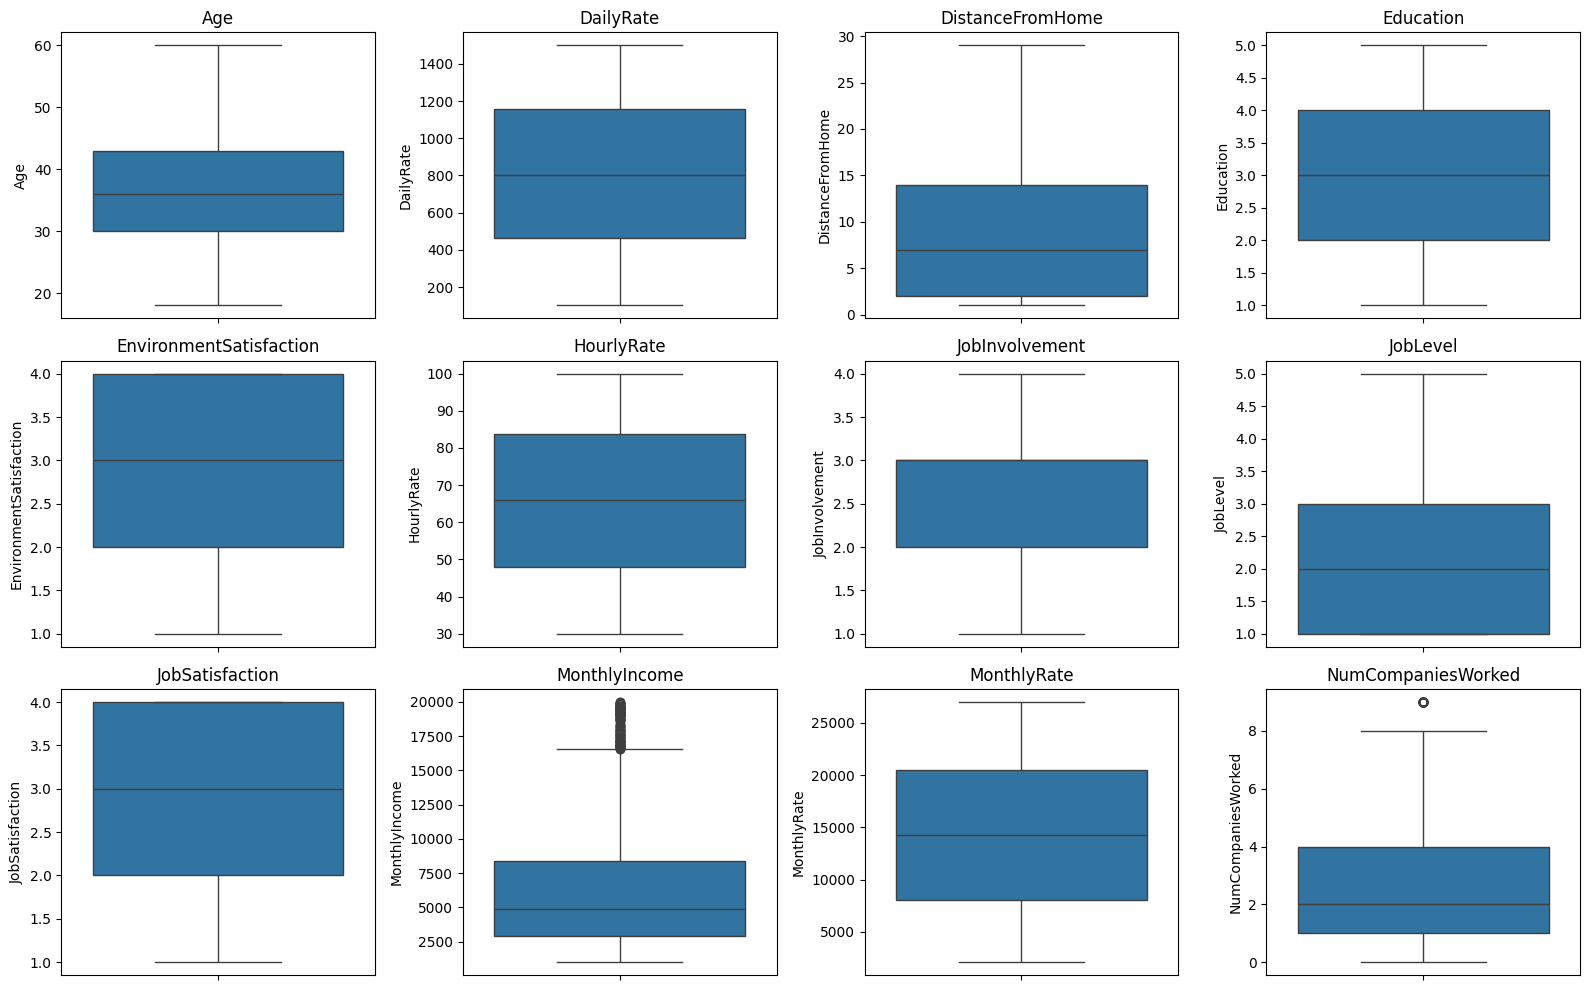

In [9]:
plt.figure(figsize=(16, 10))

for i, col in enumerate(numeric_columns[:12]):
    plt.subplot(3, 4, i + 1)
    sns.boxplot(y=df_clean[col])
    plt.title(col)
    plt.tight_layout()

plt.show()

**Create derived HR features**

In [10]:
df_engineered = df_clean.copy()

# 1. Total Employee Satisfaction
satisfaction_columns = [
    'EnvironmentSatisfaction',
    'JobSatisfaction',
    'RelationshipSatisfaction',
    'WorkLifeBalance'
]

df_engineered['TotalSatisfaction'] = (
    df_engineered[satisfaction_columns].sum(axis=1)
)

# 2. Employee Tenure Ratio
df_engineered['TenureRatio'] = np.where(
    df_engineered['TotalWorkingYears'] > 0,
    df_engineered['YearsAtCompany'] /
    df_engineered['TotalWorkingYears'],
    0
)

# 3. Career Start Age
df_engineered['CareerStartAge'] = (
    df_engineered['Age'] -
    df_engineered['TotalWorkingYears']
)

print("New HR Features Created Successfully!")

display(
    df_engineered[
        [
            'TotalSatisfaction',
            'TenureRatio',
            'CareerStartAge'
        ]
    ].head()
)

New HR Features Created Successfully!


,TotalSatisfaction,TenureRatio,CareerStartAge
0,8,0.750000,33
1,12,1.000000,39
2,12,0.000000,30
3,13,1.000000,25
4,10,0.333333,21


**Check the engineered dataset**

In [11]:
print("Original Dataset Shape:", df_clean.shape)

print("Engineered Dataset Shape:",
      df_engineered.shape)

print("\nNew Features:")
print([
    'TotalSatisfaction',
    'TenureRatio',
    'CareerStartAge'
])

display(df_engineered.head())

Original Dataset Shape: (1470, 35)
Engineered Dataset Shape: (1470, 38)

New Features:
['TotalSatisfaction', 'TenureRatio', 'CareerStartAge']


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,TotalSatisfaction,TenureRatio,CareerStartAge
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,8,0,1,6,4,0,5,8,0.750000,33
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,10,3,3,10,7,1,7,12,1.000000,39
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,7,3,3,0,0,0,0,12,0.000000,30
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,8,3,3,8,7,3,0,13,1.000000,25
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,6,3,3,2,2,2,2,10,0.333333,21


**Separate numerical and categorical variables**

In [12]:
# Separate target variable
X = df_engineered.drop(columns=['Attrition'])
y = df_engineered['Attrition'].map({
    'Yes': 1,
    'No': 0
})

# Remove identifier and constant columns
columns_to_drop = [
    'EmployeeNumber',
    'EmployeeCount',
    'Over18',
    'StandardHours'
]

X = X.drop(
    columns=columns_to_drop,
    errors='ignore'
)

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

print("\nNumerical Columns:")
print(numerical_features)

print("\nCategorical Columns:")
print(categorical_features)

print("\nTarget Variable Distribution:")
print(y.value_counts())

Numerical Features: 26
Categorical Features: 7

Numerical Columns:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'TotalSatisfaction', 'TenureRatio', 'CareerStartAge']

Categorical Columns:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Target Variable Distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64


**Encode categorical variables and scale numerical variables**

In [14]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

print("Numerical and categorical preprocessing configured!")

Numerical and categorical preprocessing configured!


**Create the complete preprocessing pipeline**

In [15]:
# Create complete preprocessing pipeline
preprocessing_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor)
])

# Fit and transform the dataset
X_processed = preprocessing_pipeline.fit_transform(X)

# Convert sparse matrix to dense array if necessary
if hasattr(X_processed, 'toarray'):
    X_processed = X_processed.toarray()

# Get transformed feature names
feature_names = (
    preprocessing_pipeline
    .named_steps['preprocessor']
    .get_feature_names_out()
)

# Create processed DataFrame
processed_df = pd.DataFrame(
    X_processed,
    columns=feature_names,
    index=X.index
)

# Add target variable
processed_df['Attrition'] = y

print("Preprocessing Pipeline Executed Successfully!")

print("Original Features:", X.shape[1])
print("Processed Features:", processed_df.shape[1] - 1)

display(processed_df.head())

Preprocessing Pipeline Executed Successfully!
Original Features: 33
Processed Features: 54


,num__Age,num__DailyRate,num__DistanceFromHome,num__Education,num__EnvironmentSatisfaction,num__HourlyRate,num__JobInvolvement,num__JobLevel,num__JobSatisfaction,num__MonthlyIncome,...,cat__JobRole_Research Director,cat__JobRole_Research Scientist,cat__JobRole_Sales Executive,cat__JobRole_Sales Representative,cat__MaritalStatus_Divorced,cat__MaritalStatus_Married,cat__MaritalStatus_Single,cat__OverTime_No,cat__OverTime_Yes,Attrition
0,0.446350,0.742527,-1.010909,-0.891688,-0.660531,1.383138,0.379672,-0.057788,1.153254,-0.108350,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1
1,1.322365,-1.297775,-0.147150,-1.868426,0.254625,-0.240677,-1.026167,-0.057788,-0.660853,-0.291719,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0
2,0.008343,1.414363,-0.887515,-0.891688,1.169781,1.284725,-1.026167,-0.961486,0.246200,-0.937654,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1
3,-0.429664,1.461466,-0.764121,1.061787,1.169781,-0.486709,0.379672,-0.961486,0.246200,-0.763634,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0
4,-1.086676,-0.524295,-0.887515,-1.868426,-1.575686,-1.274014,0.379672,-0.961486,-0.660853,-0.644858,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0


**Export processed data and reports**

In [16]:
# Export clean dataset
df_engineered.to_csv(
    'Clean_Dataset.csv',
    index=False
)

# Export processed dataset
processed_df.to_csv(
    'Processed_Dataset.csv',
    index=False
)

print("Both datasets exported successfully!")
print("Clean Dataset Shape:", df_engineered.shape)
print("Processed Dataset Shape:", processed_df.shape)

Both datasets exported successfully!
Clean Dataset Shape: (1470, 38)
Processed Dataset Shape: (1470, 55)


**Generate Data Cleaning Report**

In [17]:
cleaning_report = f"""
DATA CLEANING REPORT
====================================

Project: Enterprise Data Preparation
Dataset: IBM HR Analytics Employee Attrition

1. DATASET OVERVIEW
Original Rows: {df.shape[0]}
Original Columns: {df.shape[1]}

2. MISSING VALUE ANALYSIS
Original Missing Values: {df.isnull().sum().sum()}
Remaining Missing Values: {df_clean.isnull().sum().sum()}

3. DUPLICATE ANALYSIS
Original Duplicate Records: {df.duplicated().sum()}
Remaining Duplicate Records: {df_clean.duplicated().sum()}

4. OUTLIER DETECTION
Method: Interquartile Range (IQR)
Potential outliers were identified and reported.
Valid employee records were not automatically deleted.

5. DATASET AFTER CLEANING
Rows: {df_clean.shape[0]}
Columns: {df_clean.shape[1]}

6. CONCLUSION
Missing values and duplicate records were handled.
Potential outliers were identified for further review.
"""

with open('Data_Cleaning_Report.txt', 'w') as f:
    f.write(cleaning_report)

print(cleaning_report)


DATA CLEANING REPORT

Project: Enterprise Data Preparation
Dataset: IBM HR Analytics Employee Attrition

1. DATASET OVERVIEW
Original Rows: 1470
Original Columns: 35

2. MISSING VALUE ANALYSIS
Original Missing Values: 0
Remaining Missing Values: 0

3. DUPLICATE ANALYSIS
Original Duplicate Records: 0
Remaining Duplicate Records: 0

4. OUTLIER DETECTION
Method: Interquartile Range (IQR)
Potential outliers were identified and reported.
Valid employee records were not automatically deleted.

5. DATASET AFTER CLEANING
Rows: 1470
Columns: 35

6. CONCLUSION
Missing values and duplicate records were handled.
Potential outliers were identified for further review.



**Generate Feature Engineering Report**

In [18]:
feature_report = f"""
FEATURE ENGINEERING REPORT
====================================

1. PROJECT
Enterprise Data Preparation for Employee Attrition

2. FEATURES CREATED

A. TotalSatisfaction
Sum of employee environment, job,
relationship and work-life balance satisfaction.

B. TenureRatio
YearsAtCompany divided by TotalWorkingYears.
Zero is assigned when TotalWorkingYears is zero.

C. CareerStartAge
Age minus TotalWorkingYears.

3. CATEGORICAL ENCODING
Method: One-Hot Encoding

4. NUMERICAL SCALING
Method: StandardScaler

5. TARGET VARIABLE
Attrition:
Yes = 1
No = 0

6. FINAL DATASET
Original Feature Count: {X.shape[1]}
Processed Feature Count: {processed_df.shape[1] - 1}

7. CONCLUSION
Feature engineering and preprocessing were
performed to prepare the HR dataset for
machine learning applications.
"""

with open('Feature_Engineering_Report.txt', 'w') as f:
    f.write(feature_report)

print(feature_report)


FEATURE ENGINEERING REPORT

1. PROJECT
Enterprise Data Preparation for Employee Attrition

2. FEATURES CREATED

A. TotalSatisfaction
Sum of employee environment, job,
relationship and work-life balance satisfaction.

B. TenureRatio
YearsAtCompany divided by TotalWorkingYears.
Zero is assigned when TotalWorkingYears is zero.

C. CareerStartAge
Age minus TotalWorkingYears.

3. CATEGORICAL ENCODING
Method: One-Hot Encoding

4. NUMERICAL SCALING
Method: StandardScaler

5. TARGET VARIABLE
Attrition:
Yes = 1
No = 0

6. FINAL DATASET
Original Feature Count: 33
Processed Feature Count: 54

7. CONCLUSION
Feature engineering and preprocessing were
performed to prepare the HR dataset for
machine learning applications.



**Generate Pipeline Documentation**

In [19]:
pipeline_documentation = """
PREPROCESSING PIPELINE DOCUMENTATION
======================================

PROJECT:
Enterprise Data Preparation for Employee Attrition

TOOLS:
Python, Pandas, NumPy, Scikit-learn

PIPELINE COMPONENTS:

1. DATA IMPORT
Import the IBM HR Analytics dataset.

2. DATA CLEANING
Handle missing values and duplicates.

3. OUTLIER DETECTION
Identify potential outliers using IQR.

4. FEATURE ENGINEERING
Create TotalSatisfaction, TenureRatio
and CareerStartAge.

5. NUMERICAL PREPROCESSING
SimpleImputer using median.
StandardScaler for numerical scaling.

6. CATEGORICAL PREPROCESSING
SimpleImputer using most frequent value.
OneHotEncoder for categorical encoding.

7. COLUMN TRANSFORMATION
ColumnTransformer combines both preprocessing
pipelines.

8. PIPELINE EXECUTION
Scikit-learn Pipeline combines preprocessing
operations into a reusable workflow.

9. EXPORT
Save cleaned and processed datasets as CSV files.

NOTE:
For future predictive modelling, fit the
preprocessing pipeline on training data only.

CONCLUSION:
The pipeline provides a structured and reusable
approach to HR data preparation.
"""

with open('Pipeline_Documentation.txt', 'w') as f:
    f.write(pipeline_documentation)

print("Pipeline documentation generated!")

Pipeline documentation generated!


**Save the preprocessing pipeline**

In [20]:
import joblib

joblib.dump(
    preprocessing_pipeline,
    'Employee_Attrition_Preprocessing_Pipeline.pkl'
)

print("Preprocessing pipeline saved successfully!")

Preprocessing pipeline saved successfully!


**Final verification**

In [21]:
print("========== FINAL PROJECT VERIFICATION ==========")

print("Clean Dataset:", df_engineered.shape)
print("Processed Dataset:", processed_df.shape)

print("Missing Values in Clean Dataset:",
      df_engineered.isnull().sum().sum())

print("Duplicate Records in Clean Dataset:",
      df_engineered.duplicated().sum())

print("Missing Values in Processed Dataset:",
      processed_df.isnull().sum().sum())

print("\nGenerated Files:")

files_to_check = [
    'Clean_Dataset.csv',
    'Processed_Dataset.csv',
    'Data_Cleaning_Report.txt',
    'Feature_Engineering_Report.txt',
    'Pipeline_Documentation.txt',
    'Employee_Attrition_Preprocessing_Pipeline.pkl'
]

for file in files_to_check:
    print(file, ":", "Created" if os.path.exists(file) else "Missing")

========== FINAL PROJECT VERIFICATION ==========
Clean Dataset: (1470, 38)
Processed Dataset: (1470, 55)
Missing Values in Clean Dataset: 0
Duplicate Records in Clean Dataset: 0
Missing Values in Processed Dataset: 0

Generated Files:
Clean_Dataset.csv : Created
Processed_Dataset.csv : Created
Data_Cleaning_Report.txt : Created
Feature_Engineering_Report.txt : Created
Pipeline_Documentation.txt : Created
Employee_Attrition_Preprocessing_Pipeline.pkl : Created


**Download all deliverables together**

In [22]:
import zipfile

deliverables = [
    'Clean_Dataset.csv',
    'Processed_Dataset.csv',
    'Data_Cleaning_Report.txt',
    'Feature_Engineering_Report.txt',
    'Pipeline_Documentation.txt',
    'Employee_Attrition_Preprocessing_Pipeline.pkl'
]

with zipfile.ZipFile(
    'Assignment2_Deliverables.zip',
    'w'
) as zip_file:

    for file in deliverables:
        zip_file.write(file)

from google.colab import files

files.download('Assignment2_Deliverables.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>